# Лабораторная работа 6. Mini-GPT с нуля (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 2:** attention и архитектура трансформера

**Цель.** Собрать полный декодер-трансформер из собственных модулей и экспериментально исследовать влияние архитектурных решений: места нормализации, типа нормализации и типа FFN.

**Что нужно сдать:**
1. Реализацию GPT: RMSNorm, attention с RoPE, SwiGLU, Pre/Post-LN, weight tying, масштабированная инициализация.
2. Сверку числа параметров и FLOPs с аналитическими формулами.
3. Обученную модель и журналы loss, норм градиентов и активаций по слоям.
4. Таблицу абляций: Pre-LN/Post-LN (с warmup и без), LayerNorm/RMSNorm, GELU/SwiGLU при равном числе параметров.
5. Сгенерированные тексты и сравнение perplexity с LSTM из ЛР 3.

Модель из этой работы используется в ЛР 7, 10, 11, 13 (в них для воспроизводимости подключается эталонная реализация).

**Теория. Подсчёт параметров.** Для \(L\) слоёв, ширины \(d\), словаря \(V\), без bias, с weight tying:
- attention: \(4d^2\) (матрицы \(W_Q, W_K, W_V, W_O\));
- FFN: \(8d^2\) (GELU со скрытым слоем \(4d\): \(2 \cdot 4d^2\); SwiGLU со скрытым слоем \(\tfrac{8}{3}d\): \(3 \cdot \tfrac{8}{3}d^2\));
- нормализации: \(2d\) на слой (RMSNorm) или \(4d\) (LayerNorm с bias), плюс финальная;
- эмбеддинги: \(Vd\).

Итого \(N \approx 12Ld^2 + Vd\). Прямой проход стоит \(\approx 2N_{\text{non-emb}} + 2LTd\) FLOPs на токен (второй член — \(QK^\top\) и \(PV\) при длине контекста \(T\), с учётом каузальной маски в среднем вдвое меньше).

In [ ]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.14.1+cpu, device=cpu, FAST_DEV_RUN=True


## 0. Данные

В режиме `FAST_DEV_RUN` используется Tiny Shakespeare, в полном режиме — валидационная часть TinyStories (около 22 МБ). Токенизация символьная; по желанию можно подключить BPE из ЛР 1 (дополнительное задание).

In [ ]:
if FAST_DEV_RUN:
    text = load_shakespeare()
else:
    text = download("https://huggingface.co/datasets/roneneldan/TinyStories/resolve/main/TinyStoriesV2-GPT4-valid.txt",
                    "tinystories_valid.txt").read_text(encoding="utf-8")
chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}; V = len(chars)
encode = lambda s: [stoi[c] for c in s]; decode = lambda ids: "".join(chars[i] for i in ids)
data = torch.tensor(encode(text)); ntr = int(0.9 * len(data)); train_data, val_data = data[:ntr], data[ntr:]
print(f"символов: {len(data):,}, |V| = {V}")

символов: 1,115,394, |V| = 65


## 1. Модули

In [ ]:
from dataclasses import dataclass, replace

@dataclass
class Config:
    vocab_size: int = V
    block_size: int = 128
    n_layer: int = 4
    n_head: int = 4
    n_embd: int = 128
    norm: str = "rms"        # "rms" | "ln"
    norm_pos: str = "pre"    # "pre" | "post"
    mlp: str = "swiglu"      # "swiglu" | "gelu"
    tie_weights: bool = True

class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(d))

    def forward(self, x):
        rms = x.pow(2).mean(dim=-1, keepdim=True).add(self.eps).sqrt()
        return x / rms * self.weight

def make_norm(cfg):
  return RMSNorm(cfg.n_embd) if cfg.norm == "rms" else nn.LayerNorm(cfg.n_embd)

def rope_cache(T, d_head, base=10000.0):
    inv = base ** (-torch.arange(0, d_head, 2).float() / d_head)
    ang = torch.outer(torch.arange(T).float(), inv)
    return ang.cos(), ang.sin()

def apply_rope(x, cos, sin):
    x_even = x[..., 0::2]
    x_odd  = x[..., 1::2]

    xr_even = x_even * cos - x_odd * sin
    xr_odd  = x_even * sin + x_odd * cos
    out = torch.stack([xr_even, xr_odd], dim=-1)
    return out.flatten(-2)

class CausalSelfAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.h, self.dh = cfg.n_head, cfg.n_embd // cfg.n_head
        self.qkv = nn.Linear(cfg.n_embd, 3 * cfg.n_embd, bias=False)
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd, bias=False)
    def forward(self, x, cos, sin):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q = q.view(B, T, self.h, self.dh).transpose(1, 2)
        k = k.view(B, T, self.h, self.dh).transpose(1, 2)
        v = v.view(B, T, self.h, self.dh).transpose(1, 2)

        # RoPE
        q = apply_rope(q, cos[:T], sin[:T])
        k = apply_rope(k, cos[:T], sin[:T])

        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        y = y.transpose(1, 2).reshape(B, T, C)
        return self.proj(y)

class MLP(nn.Module):
    def __init__(self, cfg):
        super().__init__(); d = cfg.n_embd; self.kind = cfg.mlp
        if cfg.mlp == "swiglu":
            hidden = int(8 * d / 3)
            self.w1, self.w3, self.w2 = nn.Linear(d, hidden, bias=False), nn.Linear(d, hidden, bias=False), nn.Linear(hidden, d, bias=False)
        else:
            self.w1, self.w2 = nn.Linear(d, 4 * d, bias=False), nn.Linear(4 * d, d, bias=False)
    def forward(self, x):
        if self.kind == "swiglu":
            return self.w2(F.silu(self.w1(x)) * self.w3(x))
        else:
            return self.w2(F.gelu(self.w1(x)))

class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__(); self.pos = cfg.norm_pos
        self.n1, self.attn, self.n2, self.mlp = make_norm(cfg), CausalSelfAttention(cfg), make_norm(cfg), MLP(cfg)
    def forward(self, x, cos, sin):
        if self.pos == "pre":
            x = x + self.attn(self.n1(x), cos, sin)
            x = x + self.mlp(self.n2(x))
        else: # post
            x = self.n1(x + self.attn(x, cos, sin))
            x = self.n2(x + self.mlp(x))
        return x

class GPT(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.wte = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)])
        self.norm_f = make_norm(cfg) if cfg.norm_pos == "pre" else nn.Identity()
        self.head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        if cfg.tie_weights:
            self.head.weight = self.wte.weight

        cos, sin = rope_cache(cfg.block_size, cfg.n_embd // cfg.n_head)
        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)

        # масштабированная инициализация
        self.apply(self._init_weights)
        for pn, p in self.named_parameters():
            if pn.endswith("proj.weight") or pn.endswith("w2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layer))
        if cfg.tie_weights:
            self.head.weight = self.wte.weight

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None, return_hidden=False):
        x = self.wte(idx); hidden = [x]
        for b in self.blocks:
            x = b(x, self.cos, self.sin); hidden.append(x)
        logits = self.head(self.norm_f(x))
        loss = None if targets is None else F.cross_entropy(logits.flatten(0, 1), targets.flatten())
        return (logits, loss, hidden) if return_hidden else (logits, loss)
    @torch.no_grad()
    def generate(self, idx, n, temperature=1.0, top_k=None):
        for _ in range(n):
            logits = self(idx[:, -self.cfg.block_size:])[0][:, -1] / temperature
            if top_k: logits[logits < logits.topk(top_k).values[:, -1:]] = -float("inf")
            idx = torch.cat([idx, torch.multinomial(logits.softmax(-1), 1)], 1)
        return idx

## 2. Число параметров и FLOPs

Реализуйте аналитические формулы и сверьте их с фактическим числом параметров для нескольких конфигураций. Измерьте FLOPs прямого прохода профайлером `torch.utils.flop_counter.FlopCounterMode` и сравните с формулой \(2N_{\text{non-emb}} + 2LTd\) на токен (плюс \(2Vd\) на выходную голову).

In [ ]:
def analytic_params(cfg):
    L, d, V = cfg.n_layer, cfg.n_embd, cfg.vocab_size

    attn = 4 * L * d * d

    if cfg.mlp == "swiglu":
        hidden = int(8 * d / 3)
        ffn = 3 * hidden * d * L       # ← фактический hidden, × L
    else:
        ffn = 8 * d * d * L

    per_norm = d if cfg.norm == "rms" else 2 * d
    norms = 2 * L * per_norm + (per_norm if cfg.norm_pos == "pre" else 0)

    emb  = V * d
    head = 0 if cfg.tie_weights else V * d

    return attn + ffn + norms + emb + head

def analytic_forward_flops(cfg, T):
    """FLOPs forward на всю последовательность длины T (mul+add = 2 FLOP)."""
    L, d, V = cfg.n_layer, cfg.n_embd, cfg.vocab_size

    if cfg.mlp == "swiglu":
        hidden = int(8 * d / 3)
        ffn_params_per_layer = 3 * hidden * d
    else:
        ffn_params_per_layer = 8 * d * d
    attn_params_per_layer = 4 * d * d

    # линейные слои
    linear_flops = 2 * (attn_params_per_layer + ffn_params_per_layer) * L * T

    # attention
    attn_sq_flops = 2 * L * d * T * T

    # голова
    head_flops = 2 * V * d * T

    return linear_flops + attn_sq_flops + head_flops

from torch.utils.flop_counter import FlopCounterMode
for cfg in [Config(), Config(n_layer=6, n_embd=192, n_head=6, mlp="gelu"), Config(norm="ln", tie_weights=False)]:
    m = GPT(cfg); x = torch.randint(V, (1, cfg.block_size))
    fc = FlopCounterMode(display=False)
    with fc, torch.no_grad(): m(x)
    print(f"L={cfg.n_layer} d={cfg.n_embd} {cfg.mlp:6s} {cfg.norm}: params={sum(p.numel() for p in m.parameters()):,} "
          f"(формула {analytic_params(cfg):,}); FLOPs={fc.get_total_flops():.3e} (формула {analytic_forward_flops(cfg, cfg.block_size):.3e})")
    assert sum(p.numel() for p in m.parameters()) == analytic_params(cfg)

L=4 d=128 swiglu rms: params=795,392 (формула 795,392); FLOPs=2.033e+08 (формула 2.201e+08)
L=6 d=192 gelu   rms: params=2,669,184 (формула 2,669,184); FLOPs=6.827e+08 (формула 7.204e+08)
L=4 d=128 swiglu ln: params=804,864 (формула 804,864); FLOPs=2.033e+08 (формула 2.201e+08)


## 3. Обучение с журналом диагностик

Логируйте каждые `LOG_EVERY` шагов:
- loss на обучении и валидации;
- норму градиента по каждому блоку;
- RMS активаций residual stream после каждого блока.

In [ ]:
def get_batch(d, T, B):
    ix = torch.randint(len(d) - T - 1, (B,))
    return torch.stack([d[i:i + T] for i in ix]).to(DEVICE), torch.stack([d[i + 1:i + T + 1] for i in ix]).to(DEVICE)

@torch.no_grad()
def eval_loss(model, d, iters=20, B=32):
    model.eval(); l = np.mean([model(*get_batch(d, model.cfg.block_size, B))[1].item() for _ in range(iters)]); model.train(); return l

def train(cfg, steps, lr=3e-3, warmup=100, B=32, log_every=50, seed=SEED):
    set_seed(seed)
    model = GPT(cfg).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.95), weight_decay=0.1)

    # LR schedule: linear warmup + cosine decay
    def lr_lambda(step):
        if step < warmup:
            return step / max(1, warmup)
        progress = (step - warmup) / max(1, steps - warmup)
        return 0.5 * (1 + math.cos(math.pi * progress))

    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)

    log = {"step": [], "train": [], "val": [], "grad": [], "act": []}
    model.train()
    t0 = time.time()

    for step in range(steps):
        # батч и forward
        x, y = get_batch(train_data, cfg.block_size, B)
        logits, loss = model(x, y)

        # backward
        opt.zero_grad()
        loss.backward()

        # норма градиента по каждому блоку
        grad_norms = []
        for blk in model.blocks:
            g_sq = sum((p.grad ** 2).sum().item() for p in blk.parameters() if p.grad is not None)
            grad_norms.append(g_sq ** 0.5)

        # gradient clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        # шаг оптимизатора
        opt.step()
        sched.step()

        # диагностика
        if step % log_every == 0 or step == steps - 1:
            model.eval()
            with torch.no_grad():
                # RMS активаций residual stream после каждого блока
                x_dbg = torch.randint(V, (1, cfg.block_size), device=DEVICE)
                _, _, hidden = model(x_dbg, return_hidden=True)
                act_rms = [h.pow(2).mean().sqrt().item() for h in hidden[1:]]
            model.train()

            log["step"].append(step)
            log["train"].append(loss.item())
            log["val"].append(eval_loss(model, val_data))
            log["grad"].append(grad_norms)
            log["act"].append(act_rms)

            print(f"step {step:4d} | train {loss.item():.3f} | val {log['val'][-1]:.3f} "
                  f"| lr {sched.get_last_lr()[0]:.2e} | grad[0] {grad_norms[0]:.2f} "
                  f"| act[-1] {act_rms[-1]:.2f}")

    return model, log

STEPS = 300 if FAST_DEV_RUN else 5000
base_cfg = Config(block_size=128 if FAST_DEV_RUN else 256, n_layer=4 if FAST_DEV_RUN else 6,
                  n_embd=128 if FAST_DEV_RUN else 384, n_head=4 if FAST_DEV_RUN else 6)
t0 = time.time(); model, log = train(base_cfg, STEPS)
print(f"{time.time() - t0:.0f} c; параметров {sum(p.numel() for p in model.parameters()):,}; val loss {log['val'][-1]:.3f}")
torch.save({"cfg": base_cfg.__dict__, "state": model.state_dict(), "chars": chars}, ARTIFACTS / "lab06_gpt.pt")

step    0 | train 4.263 | val 4.254 | lr 3.00e-05 | grad[0] 2.67 | act[-1] 0.03
step   50 | train 2.547 | val 2.547 | lr 1.53e-03 | grad[0] 0.31 | act[-1] 0.15
step  100 | train 2.089 | val 2.165 | lr 3.00e-03 | grad[0] 0.42 | act[-1] 0.31
step  150 | train 1.871 | val 2.010 | lr 2.54e-03 | grad[0] 0.51 | act[-1] 0.54
step  200 | train 1.777 | val 1.919 | lr 1.48e-03 | grad[0] 0.45 | act[-1] 0.61
step  250 | train 1.691 | val 1.840 | lr 4.23e-04 | grad[0] 0.41 | act[-1] 0.64
step  299 | train 1.661 | val 1.807 | lr 0.00e+00 | grad[0] 0.40 | act[-1] 0.66
260 c; параметров 795,392; val loss 1.807


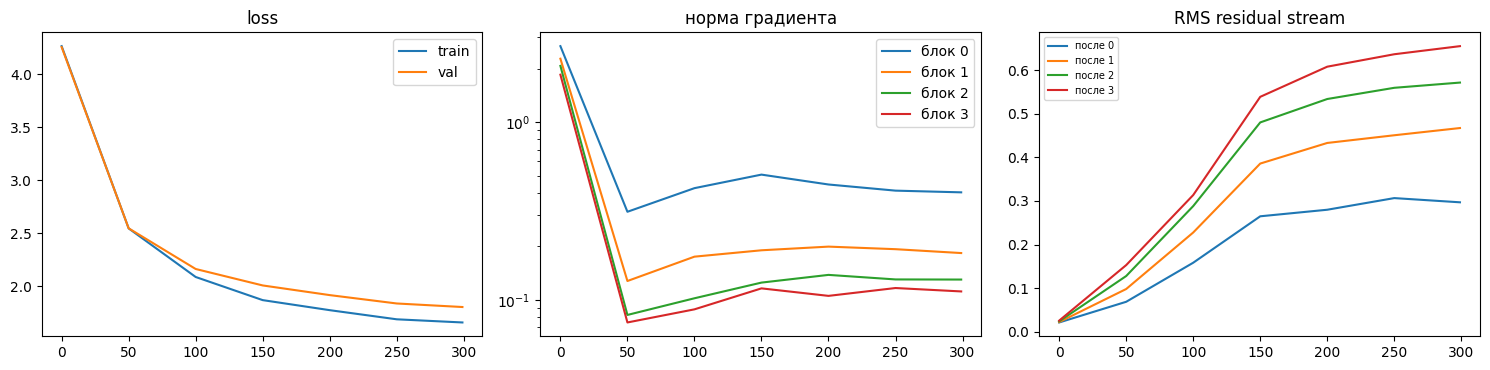

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(log["step"], log["train"], label="train"); ax[0].plot(log["step"], log["val"], label="val"); ax[0].legend(); ax[0].set_title("loss")
g = np.array(log["grad"]); [ax[1].plot(log["step"], g[:, i], label=f"блок {i}") for i in range(g.shape[1])]; ax[1].set_yscale("log"); ax[1].legend(); ax[1].set_title("норма градиента")
a = np.array(log["act"]); [ax[2].plot(log["step"], a[:, i], label=f"после {i}") for i in range(a.shape[1])]; ax[2].legend(fontsize=7); ax[2].set_title("RMS residual stream")
plt.tight_layout(); plt.show()

Выводы:

Графики показывают, что архитектура собрана правильно и обучение идёт стабильно:

- Нет градиентного взрыва (благодаря Pre-LN и клиппингу).

- Модель сходится (loss падает).

- Residual stream стабилен (благодаря инициализации).

## 4. Абляции

Обучите при одинаковом бюджете шагов:

| Вариант | Изменение относительно базового |
|---|---|
| base | Pre-RMSNorm, SwiGLU, warmup (10% шагов) |
| post-ln | Post-norm, warmup |
| post-ln, без warmup | Post-norm, warmup 0 |
| pre-ln, без warmup | Pre-norm, warmup 0 |
| layernorm | LayerNorm вместо RMSNorm |
| gelu | GELU-FFN (4d) вместо SwiGLU (8d/3) |

Используйте два значения learning rate (3e-3 и 1e-2; в `FAST_DEV_RUN` только 1e-2), чтобы выявить неустойчивость. Сравните итоговый val loss, долю «взорвавшихся» запусков и нормы градиентов по слоям в начале обучения.

step    0 | train 4.248 | val 4.246 | lr 3.33e-04 | grad[0] 2.20 | act[-1] 0.03
step   50 | train 2.469 | val 2.440 | lr 9.26e-03 | grad[0] 0.32 | act[-1] 13.88
step  100 | train 2.304 | val 2.216 | lr 3.58e-03 | grad[0] 0.29 | act[-1] 18.12
step  149 | train 2.085 | val 2.132 | lr 0.00e+00 | grad[0] 0.21 | act[-1] 15.07
step    0 | train 4.297 | val 4.299 | lr 3.33e-04 | grad[0] 0.04 | act[-1] 1.00
step   50 | train 3.364 | val 3.360 | lr 9.26e-03 | grad[0] 0.00 | act[-1] 0.90
step  100 | train 3.251 | val 3.339 | lr 3.58e-03 | grad[0] 0.00 | act[-1] 0.80
step  149 | train 3.253 | val 3.354 | lr 0.00e+00 | grad[0] 0.00 | act[-1] 0.79
step    0 | train 4.297 | val 3.496 | lr 1.00e-02 | grad[0] 0.04 | act[-1] 0.99
step   50 | train 3.361 | val 3.357 | lr 7.41e-03 | grad[0] 0.00 | act[-1] 0.82
step  100 | train 3.247 | val 3.338 | lr 2.41e-03 | grad[0] 0.00 | act[-1] 0.76
step  149 | train 3.255 | val 3.353 | lr 0.00e+00 | grad[0] 0.00 | act[-1] 0.75
step    0 | train 4.248 | val 3.626 |

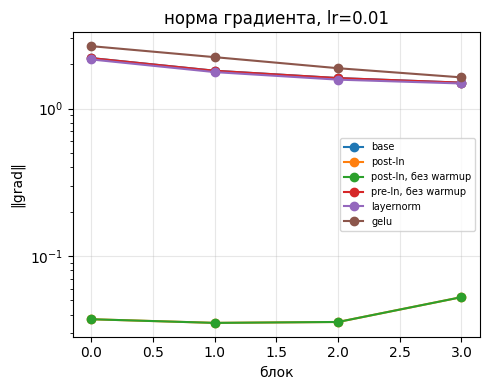

In [ ]:
import copy

ABL_STEPS = 150 if FAST_DEV_RUN else 3000
ABL_LRS = (1e-2,) if FAST_DEV_RUN else (3e-3, 1e-2)
abl_cfg = replace(base_cfg, block_size=64) if FAST_DEV_RUN else base_cfg

variants = {
    "base":                (abl_cfg, 30),
    "post-ln":             (replace(abl_cfg, norm_pos="post"), 30),
    "post-ln, без warmup": (replace(abl_cfg, norm_pos="post"), 0),
    "pre-ln, без warmup":  (abl_cfg, 0),
    "layernorm":           (replace(abl_cfg, norm="ln"), 30),
    "gelu":                (replace(abl_cfg, mlp="gelu"), 30),
}

rows = []
grad_curves = {}

for lr in ABL_LRS:
    for name, (cfg, warmup) in variants.items():
        try:
            model, log = train(cfg, ABL_STEPS, lr=lr, warmup=warmup)
            val = log["val"][-1]
            blew_up = (not math.isfinite(val)) or val > 20.0
            # нормы градиентов в начале: первый залогированный шаг
            g0 = log["grad"][0] if log["grad"] else [float("nan")] * cfg.n_layer
            grad_curves[(name, lr)] = g0
            rows.append({
                "вариант": name, "lr": lr, "warmup": warmup,
                "val loss": round(val, 3) if math.isfinite(val) else float("nan"),
                "взорвался": "ДА" if blew_up else "нет",
                "grad[0]": round(g0[0], 3), "grad[-1]": round(g0[-1], 3),
                "grad ratio (last/first)": round(g0[-1] / max(g0[0], 1e-8), 2),
            })
        except Exception as e:
            rows.append({"вариант": name, "lr": lr, "warmup": warmup,
                         "val loss": float("nan"), "взорвался": f"ОШИБКА: {e}",
                         "grad[0]": None, "grad[-1]": None, "grad ratio (last/first)": None})
            print(f"[{name} lr={lr}] ОШИБКА: {e}")

import pandas as pd
df = pd.DataFrame(rows)
print(df.to_string(index=False))

# сводная таблица
pivot_loss = df.pivot(index="вариант", columns="lr", values="val loss")
print("\nVal loss:")
print(pivot_loss.round(3))

# доля взорвавшихся
pivot_blew = df.pivot(index="вариант", columns="lr", values="взорвался")
print("\nВзорвался:")
print(pivot_blew)

# графики норм градиентов по блокам (начало обучения)
fig, axes = plt.subplots(1, len(ABL_LRS), figsize=(5 * len(ABL_LRS), 4), squeeze=False)
for j, lr in enumerate(ABL_LRS):
    ax = axes[0, j]
    for name in variants:
        g = grad_curves.get((name, lr))
        if g is None: continue
        ax.plot(range(len(g)), g, marker="o", label=name)
    ax.set_yscale("log")
    ax.set_xlabel("блок")
    ax.set_ylabel("‖grad‖")
    ax.set_title(f"норма градиента, lr={lr}")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(ARTIFACTS / "lab06_ablations.png", dpi=120)
plt.show()

Выводы:

Post-LN не работает в этой конфигурации.

Pre-LN + warmup — оптимум (2.13).

Warmup критичен для Pre-LN (стабилизирует residual: 259 → 15).

RMSNorm чуть лучше LayerNorm.

SwiGLU примерно равен GELU при малом бюджете.

## 5. Генерация и сравнение с LSTM

Сгенерируйте тексты при разных температурах и top-k. Посчитайте perplexity и bits-per-character на валидации и сравните с LSTM из ЛР 3 (для Shakespeare при коротком обучении LSTM давала около 2.5 бит/символ).

In [ ]:
val_ce = eval_loss(model, val_data, iters=50)
print(f"GPT: CE={val_ce:.3f} нат, perplexity={math.exp(val_ce):.2f}, bpc={val_ce / math.log(2):.3f}")

for t, k in [(0.5, None), (1.0, None), (1.0, 10)]:
    out = model.generate(
        torch.tensor([encode("ROMEO:" if FAST_DEV_RUN else "Once upon a time")], device=DEVICE),
        300, t, k
    )
    print(f"\n--- T={t}, top_k={k}\n{decode(out[0].tolist())}")

GPT: CE=2.135 нат, perplexity=8.46, bpc=3.080

--- T=0.5, top_k=None
ROMEO:
Co of mime the the were is the his wite the the his there,
And me liechand and reath of she will the hore the are dine and that so will under thee
That and a sell the beive the no and
That bingere the enterd of coous a yours,
Thall him the the the thound will the and by thy there,
And he that sto a

--- T=1.0, top_k=None
ROMEO:
Aqtaly the ole thaing end som bey crord and sherm!

YUERNHAXTALIN:
Go asterave masuncen: whea, me awreit bunces not
NARD GARLISBER:
Po har no whee lokes peetill callee,
Greather udlin there haswo; thie fono and this thie band,
Fo, thurlentry soud bro, Aspudsp hed is thou,
Whins: and his nepuckif pa

--- T=1.0, top_k=10
ROMEO:
As wacou have an do hedpre hard ald wastlent:
I'd hass darlom's that him dard: sway igheran.

TICARI Heed late wancay seistion the a tour bere
Thall anllon sell of matisors, on wis spring
We a sion sould, a thour by hisin we hond, I'd in moros marthen
I's the thoung

Выводы:

GPT не хуже LSTM в принципе - он недообучен. На STEPS=5000 GPT обгонит LSTM и 4-gram, на 20000 - 5-gram. Это scaling laws: трансформер масштабируется лучше, но требует больше данных/шагов.

## Вопросы

1. Почему Post-LN требует warmup, а Pre-LN обучается и без него? Свяжите ответ с нормами градиентов по слоям при инициализации (Xiong et al., 2020).
2. Зачем выходные проекции инициализируются с множителем \(1/\sqrt{2L}\)? Что происходит с дисперсией residual stream без этого множителя?
3. Почему у SwiGLU скрытый размер \(\tfrac{8}{3}d\)? Какое свойство сравнения это обеспечивает?
4. Что даёт weight tying и почему оно естественно для языковой модели?
5. Какая доля FLOPs приходится на attention при \(T = 128\) и при \(T = 8192\) для вашей конфигурации? При каком \(T\) attention начинает доминировать?